# Adaptive conformal intervals for house prices

Make conformal intervals as wide as each prediction is uncertain, and keep their 90% guarantee.

Split conformal prediction gives intervals that contain the true value at least 90% of the time
(see [conformal forecast intervals](https://anas-rz.github.io/keras-proba/examples/conformal_forecast_intervals/)
for the recipe). Applied to a point prediction, every interval gets **the same width**. But some
prices are much easier to predict than others: a fixed width is too wide for the easy ones and
too narrow for the hard ones.

If the model also predicts its uncertainty, conformal prediction can measure the errors **in
units of that uncertainty**. The intervals then stretch and shrink with each input, and keep
their 90% guarantee.

In [ ]:
# Install keras-proba, then choose a backend: "jax", "tensorflow" or "torch".
!pip install -q keras-proba
import os

os.environ["KERAS_BACKEND"] = "jax"

## Load the data

California housing: eight features per district and the median house value ($100,000 units).
A quarter of the training data is held out for calibration.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import keras
import keras_proba

keras.utils.set_random_seed(0)
(x, y), (x_test, y_test) = keras.datasets.california_housing.load_data(version="large")
y, y_test = (y / 1e5).astype("float32")[:, None], (y_test / 1e5).astype("float32")[:, None]
mean, std = x.mean(0), x.std(0)
x, x_test = (x - mean) / std, (x_test - mean) / std
x_cal, y_cal, x_train, y_train = x[: len(x) // 4], y[: len(x) // 4], x[len(x) // 4 :], y[len(x) // 4 :]

## A model that predicts its own uncertainty

A [`GaussianHead`](https://anas-rz.github.io/keras-proba/api/layers/#keras_proba.layers.GaussianHead)
predicts a mean and a standard deviation for each district.

In [3]:
model = keras.Sequential(
    [
        keras.Input((8,)),
        keras.layers.Dense(128, activation="relu"),
        keras.layers.Dense(128, activation="relu"),
        keras_proba.layers.GaussianHead(1),
    ]
)
model.compile(optimizer="adam", loss=keras_proba.losses.GaussianNLL())
model.fit(
    x_train,
    y_train,
    validation_split=0.1,
    epochs=100,
    batch_size=128,
    callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)],
    verbose=0,
)
mean_cal, std_cal = keras_proba.ops.split_gaussian_params(model.predict(x_cal, verbose=0))
mean_test, std_test = keras_proba.ops.split_gaussian_params(model.predict(x_test, verbose=0))

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


## Constant and adaptive conformal intervals

Both are calibrated on the same held-out districts. The only difference is `scale=`.

In [4]:
constant = keras_proba.postprocessing.SplitConformalRegressor(alpha=0.1).fit(y_cal, mean_cal)
adaptive = keras_proba.postprocessing.SplitConformalRegressor(alpha=0.1).fit(y_cal, mean_cal, scale=std_cal)
intervals = {
    "constant width": constant.predict_interval(mean_test),
    "adaptive width": adaptive.predict_interval(mean_test, scale=std_test),
}

for name, (lower, upper) in intervals.items():
    coverage = float(keras.ops.convert_to_numpy(keras_proba.postprocessing.interval_coverage(y_test, lower, upper))[0])
    width = float(keras.ops.convert_to_numpy(keras.ops.mean(upper - lower)))
    print(f"{name}: contains the actual value {coverage:.1%} of the time, mean width ${width * 100:.0f}k")

constant width: contains the actual value 91.0% of the time, mean width $166k
adaptive width: contains the actual value 90.0% of the time, mean width $147k


## Where do the intervals hold?

Both are valid on average, but prices are harder to predict in some groups of districts than in
others. Split the districts by median income: the constant intervals cover some groups well
above 90% and others below it. The adaptive intervals change their width from group to group,
and keep every group close to 90%.

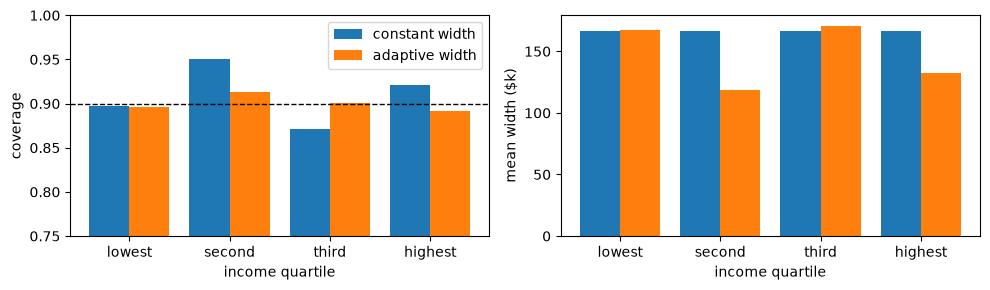

In [5]:
income = x_test[:, 0]
groups = np.digitize(income, np.quantile(income, [0.25, 0.5, 0.75]))
labels = ["lowest", "second", "third", "highest"]

fig, (ax_coverage, ax_width) = plt.subplots(1, 2, figsize=(10, 3))
for i, (name, (lower, upper)) in enumerate(intervals.items()):
    lower, upper = keras.ops.convert_to_numpy(lower)[:, 0], keras.ops.convert_to_numpy(upper)[:, 0]
    inside = (y_test[:, 0] >= lower) & (y_test[:, 0] <= upper)
    positions = np.arange(4) + 0.4 * i
    ax_coverage.bar(positions, [inside[groups == g].mean() for g in range(4)], width=0.4, label=name)
    ax_width.bar(positions, [100 * (upper - lower)[groups == g].mean() for g in range(4)], width=0.4, label=name)
ax_coverage.axhline(0.9, color="k", ls="--", lw=1)
ax_coverage.set(ylim=(0.75, 1.0), ylabel="coverage", xticks=np.arange(4) + 0.2, xticklabels=labels, xlabel="income quartile")
ax_width.set(ylabel="mean width ($k)", xticks=np.arange(4) + 0.2, xticklabels=labels, xlabel="income quartile")
ax_coverage.legend()
plt.tight_layout()
plt.show()

## What we learned

- Conformal intervals around a point prediction have a constant width, and are valid on average
  but uneven across inputs.
- Giving `SplitConformalRegressor` the model's predicted standard deviation (`scale=`) keeps the
  90% guarantee and makes the intervals adapt: narrower on average, and fairer across groups.
- The scale can come from a `GaussianHead`, a `MixtureGaussianHead`
  (`keras_proba.ops.mixture_mean_and_stddev`) or the spread of a Bayesian model's predictions.